# VoltAhead — Persistence & Majority Baselines
**Steps 3–5 (Efe) · Additional responsibility** · seed 42 · threshold 0.5 · `y_prob = P(Available = 1)`

This notebook implements the simple reference models the machine-learning models are compared against.
All probabilities are estimated **only from the approved fitting data (Dec 1–29)**. Validation and test labels are never used.

| model_name | model_version | y_prob | Role |
|---|---|---|---|
| `persistence` | `deterministic` | 1.0 if `current_idle > 0` else 0.0 | original rule, kept as reference |
| `persistence` | `probability` | `P(target=1 \| current_available, horizon)` (6-group table) | learned probability baseline |
| `majority` | `global` | global available share of Dec 1–29 labels | **required** majority baseline |
| `majority` | `horizon` | available share per horizon | optional extra |

The shared evaluation module requires `y_pred == (y_prob >= threshold)` and a single `model_name`/`model_version` per file, so the deterministic rule is stored with a hard 0/1 score (threshold 0.5) and each variant has its own `model_version`.

**Smoothing rule** (training-only): `p = (k + m·prior) / (n + m)` with `m = 10` pseudo-observations, `k` = available labels in the group, `n` = group size, `prior` = available share of the same fitting data (same horizon for persistence; global for the horizon-specific majority). An empty group (`n = 0`) falls back to the prior. With >36 000 rows per group the smoothing is practically inactive; it only protects tiny/empty groups.

In [1]:
import sys, os, json, time, platform, subprocess, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
warnings.filterwarnings("ignore", category=FutureWarning)

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
os.chdir(ROOT)
for p in (ROOT / "src", ROOT / "src" / "models"):
    sys.path.insert(0, str(p))

import preprocessing as pp
import evaluation as ev
import internal_splits as sp
SEED = 42
np.random.seed(SEED)
TABLES, FIGS, PRED, MODELS = (ROOT / "outputs" / d for d in ("tables", "figures", "predictions", "models"))
for d in (TABLES, FIGS, PRED, MODELS):
    d.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")
pd.options.display.float_format = "{:.4f}".format
pd.options.display.width = 200

def environment_info(n_jobs=None):
    mem = None
    try:
        mem = round(int(open("/proc/meminfo").read().split()[1]) / 1024**2, 1)
    except Exception:
        pass
    try:
        commit = subprocess.run(["git", "rev-parse", "HEAD"], capture_output=True, text=True, cwd=ROOT).stdout.strip() or None
    except Exception:
        commit = None
    import sklearn
    info = {"python": platform.python_version(), "os": platform.platform(), "cpu_count": os.cpu_count(),
            "ram_gb": mem, "numpy": np.__version__, "pandas": pd.__version__, "sklearn": sklearn.__version__,
            "n_jobs": n_jobs, "seed": SEED, "git_commit": commit}
    try:
        import xgboost; info["xgboost"] = xgboost.__version__
    except Exception:
        pass
    return info

import baselines as bl
ENV = environment_info(n_jobs=1)
ENV

{'python': '3.13.18',
 'os': 'Linux-6.18.44-fc-v880-x86_64-with-glibc2.39',
 'cpu_count': 2,
 'ram_gb': 7.8,
 'numpy': '2.5.3',
 'pandas': '3.0.5',
 'sklearn': '1.9.1',
 'n_jobs': 1,
 'seed': 42,
 'git_commit': None,
 'xgboost': '3.4.1'}

## 1. Load shared datasets and verify

In [2]:
def load_shared():
    """Shared Step-2 datasets; rebuilt with run_preprocessing() if the Parquet files are missing."""
    d = ROOT / "data" / "processed"
    if all((d / f"{n}.parquet").exists() for n in ("train", "validation")):
        return pd.read_parquet(d / "train.parquet"), pd.read_parquet(d / "validation.parquet")
    train, validation, _test = pp.run_preprocessing()      # test is never used for decisions
    return train, validation

train, validation = load_shared()
training_station_ids = pd.read_csv(TABLES / "training_station_ids.csv").iloc[:, 0].astype(int).tolist()
assert (len(train), len(validation)) == (2_798_569, 618_726), (len(train), len(validation))
print(f"train {len(train):,} | validation {len(validation):,}")

print("validation stations:", validation.station_id.nunique(), "| unseen:", sorted(set(validation.station_id) - set(training_station_ids)))
print("target mean  train %.4f | validation %.4f" % (train.target.mean(), validation.target.mean()))
assert set(validation.target.unique()) <= {0.0, 1.0}

train 2,798,569 | validation 618,726
validation stations: 90 | unseen: [1948]
target mean  train 0.9540 | validation 0.9582


## 2. Baseline fitting data (Dec 1–29)
Both `time` and `target_time` must lie inside Dec 1–29, so the calibration (Dec 30–Jan 2) and threshold (Jan 3–5) periods stay untouched.

In [3]:
fit = sp.get_period(train, "fit_tuning")
assert fit["time"].max() < pd.Timestamp("2022-12-30") and fit["target_time"].max() < pd.Timestamp("2022-12-30")
print(f"fitting rows: {len(fit):,} | stations: {fit.station_id.nunique()} | {fit.time.min()} -> {fit.target_time.max()}")
pd.crosstab(fit.prediction_horizon, fit.target.astype(int), margins=True)

fitting rows: 2,259,325 | stations: 91 | 2022-12-01 02:00:00 -> 2022-12-29 23:55:00


target,0,1,All
prediction_horizon,,,
30,36264,717086,753350
40,36268,716900,753168
60,36272,716535,752807
All,108804,2150521,2259325


## 3. Persistence transition table (6 groups)

In [4]:
transitions = bl.fit_persistence_transitions(fit)
transitions.to_csv(TABLES / "persistence_transition_probabilities.csv", index=False)
assert len(transitions) == 6 and transitions.n_observations.sum() == len(fit)
transitions

,current_state,current_available,prediction_horizon,n_observations,n_available,n_unavailable,raw_available_rate,prior_horizon_rate,smoothed_available_rate,smoothing_strength,fallback_used
0,unavailable,0,30,36229,2001,34228,0.0552,0.9519,0.0555,10,False
1,unavailable,0,40,36221,2144,34077,0.0592,0.9518,0.0594,10,False
2,unavailable,0,60,36208,2695,33513,0.0744,0.9518,0.0747,10,False
3,available,1,30,717121,715085,2036,0.9972,0.9519,0.9972,10,False
4,available,1,40,716947,714756,2191,0.9969,0.9518,0.9969,10,False
5,available,1,60,716599,713840,2759,0.9961,0.9518,0.9961,10,False


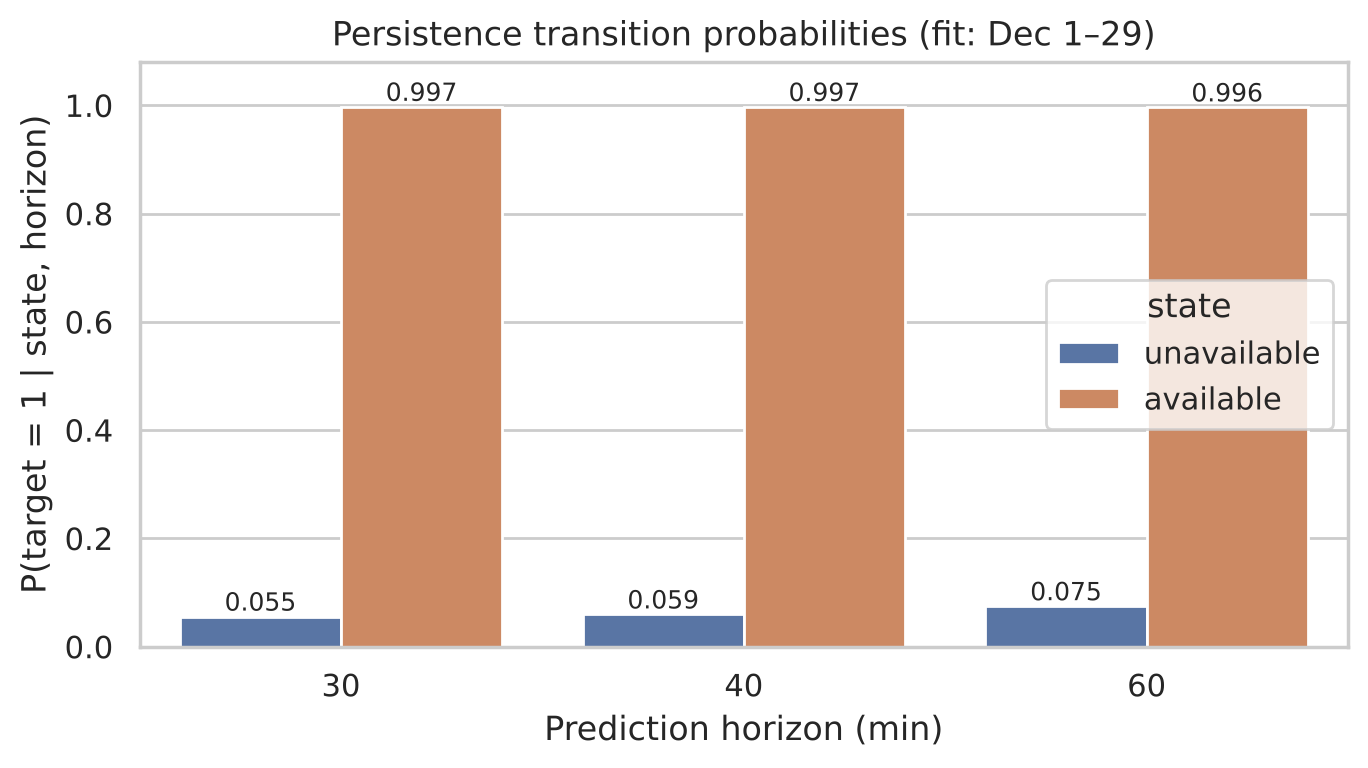

In [5]:
fig, ax = plt.subplots(figsize=(7, 4))
plot = transitions.assign(state=transitions.current_state)
sns.barplot(data=plot, x="prediction_horizon", y="smoothed_available_rate", hue="state", ax=ax)
for c in ax.containers: ax.bar_label(c, fmt="%.3f", fontsize=9)
ax.set_ylim(0, 1.08); ax.set_xlabel("Prediction horizon (min)"); ax.set_ylabel("P(target = 1 | state, horizon)")
ax.set_title("Persistence transition probabilities (fit: Dec 1–29)")
fig.tight_layout(); fig.savefig(FIGS / "persistence_transition_probabilities.png", dpi=150); plt.show()

## 4. Majority class proportions

In [6]:
majority = bl.fit_majority(fit)
majority.to_csv(TABLES / "majority_class_proportions.csv", index=False)
p_major = float(majority.loc[majority.scope == "global", "probability_used"].iloc[0])
print(f"Global P(Available=1) from training labels only: {p_major:.6f}")
majority

Global P(Available=1) from training labels only: 0.951842


,scope,prediction_horizon,n_observations,n_available,n_unavailable,available_rate,probability_used,majority_class,required
0,global,all,2259325,2150521,108804,0.9518,0.9518,1,True
1,horizon,30,753350,717086,36264,0.9519,0.9519,1,False
2,horizon,40,753168,716900,36268,0.9518,0.9518,1,False
3,horizon,60,752807,716535,36272,0.9518,0.9518,1,False


## 5. Validation predictions (all four variants, every validation row)

In [7]:
preds = bl.predict_all_baselines(validation, transitions, majority)
for (name, ver), f in preds.items():
    ev.validate_prediction_output(f, reference=validation)          # schema, one row per key, y_pred rule
    assert len(f) == len(validation)
    assert (f.y_pred == (f.y_prob >= f.threshold).astype(int)).all()
    f.to_parquet(PRED / f"{name}_{ver}_validation_predictions.parquet", index=False)
    print(f"{name}/{ver:<14} rows={len(f):,}  distinct y_prob={f.y_prob.nunique()}")

persistence/deterministic  rows=618,726  distinct y_prob=2


persistence/probability    rows=618,726  distinct y_prob=6


majority/global         rows=618,726  distinct y_prob=1


majority/horizon        rows=618,726  distinct y_prob=3


## 6. Evaluation — overall, by horizon, seen/unseen stations
Primary metric: seen-station `AP_0` (class-0 score = `1 − y_prob`). Undefined metrics are written as N/A.

In [8]:
results, overall_rows, horizon_rows, group_rows = {}, [], [], []
for (name, ver), f in preds.items():
    r = ev.export_evaluation_results(f, training_station_ids, validation, TABLES)
    results[(name, ver)] = r
    for lst, key in ((overall_rows, "overall"), (horizon_rows, "by_horizon"), (group_rows, "by_station_group")):
        lst.append(r[key])
overall = pd.concat(overall_rows, ignore_index=True)
by_horizon = pd.concat(horizon_rows, ignore_index=True)
by_group = pd.concat(group_rows, ignore_index=True)
for n, t in (("baseline_overall", overall), ("baseline_by_horizon", by_horizon), ("baseline_by_station_group", by_group)):
    t.to_csv(TABLES / f"{n}_metrics.csv", index=False, na_rep="N/A")
cols = ["model_name","model_version","n_observations","accuracy","balanced_accuracy","precision_0","recall_0","f1_0","roc_auc","ap_0","brier_score"]
overall[cols]

Saved: /home/claude/repo/outputs/tables/persistence_deterministic_overall.csv
Saved: /home/claude/repo/outputs/tables/persistence_deterministic_by_horizon.csv
Saved: /home/claude/repo/outputs/tables/persistence_deterministic_by_station_group.csv


Saved: /home/claude/repo/outputs/tables/persistence_probability_overall.csv
Saved: /home/claude/repo/outputs/tables/persistence_probability_by_horizon.csv
Saved: /home/claude/repo/outputs/tables/persistence_probability_by_station_group.csv


Saved: /home/claude/repo/outputs/tables/majority_global_overall.csv
Saved: /home/claude/repo/outputs/tables/majority_global_by_horizon.csv
Saved: /home/claude/repo/outputs/tables/majority_global_by_station_group.csv


Saved: /home/claude/repo/outputs/tables/majority_horizon_overall.csv
Saved: /home/claude/repo/outputs/tables/majority_horizon_by_horizon.csv
Saved: /home/claude/repo/outputs/tables/majority_horizon_by_station_group.csv


,model_name,model_version,n_observations,accuracy,balanced_accuracy,precision_0,recall_0,f1_0,roc_auc,ap_0,brier_score
0,persistence,deterministic,618726,0.9967,0.9803,0.9596,0.9623,0.9610,0.9803,0.9250,0.0033
1,persistence,probability,618726,0.9967,0.9803,0.9596,0.9623,0.9610,0.9821,0.9305,0.0032
2,majority,global,618726,0.9582,0.5000,NaN,0.0000,0.0000,0.5000,0.0418,0.0401
3,majority,horizon,618726,0.9582,0.5000,NaN,0.0000,0.0000,0.4999,0.0418,0.0401


In [9]:
by_group[[c for c in by_group.columns if c in cols or c in ('evaluation_group','station_group','n_stations')]]

,model_name,model_version,evaluation_group,n_stations,n_observations,accuracy,balanced_accuracy,precision_0,recall_0,f1_0,roc_auc,ap_0,brier_score
0,persistence,deterministic,seen,89,612854,0.9967,0.9805,0.9601,0.9628,0.9614,0.9805,0.9259,0.0033
1,persistence,deterministic,unseen,1,5872,0.9959,0.4990,0.0000,0.0000,0.0000,0.4990,0.0020,0.0041
2,persistence,probability,seen,89,612854,0.9967,0.9805,0.9601,0.9628,0.9614,0.9824,0.9313,0.0032
3,persistence,probability,unseen,1,5872,0.9959,0.4990,0.0000,0.0000,0.0000,0.4993,0.0020,0.0038
4,majority,global,seen,89,612854,0.9578,0.5000,NaN,0.0000,0.0000,0.5000,0.0422,0.0404
5,majority,global,unseen,1,5872,0.9980,0.5000,NaN,0.0000,0.0000,0.5000,0.0020,0.0042
6,majority,horizon,seen,89,612854,0.9578,0.5000,NaN,0.0000,0.0000,0.4999,0.0422,0.0404
7,majority,horizon,unseen,1,5872,0.9980,0.5000,NaN,0.0000,0.0000,0.5003,0.0020,0.0042


In [10]:
by_horizon[[c for c in by_horizon.columns if c in cols or c in ('prediction_horizon','evaluation_group')]]

,model_name,model_version,evaluation_group,prediction_horizon,n_observations,accuracy,balanced_accuracy,precision_0,recall_0,f1_0,roc_auc,ap_0,brier_score
0,persistence,deterministic,horizon,30,206482,0.9974,0.9841,0.9675,0.9695,0.9685,0.9841,0.9393,0.0026
1,persistence,deterministic,horizon,40,206302,0.9969,0.9811,0.9613,0.9638,0.9625,0.9811,0.9280,0.0031
2,persistence,deterministic,horizon,60,205942,0.9960,0.9757,0.9501,0.9535,0.9518,0.9757,0.9079,0.0040
3,persistence,probability,horizon,30,206482,0.9974,0.9841,0.9675,0.9695,0.9685,0.9841,0.9393,0.0026
4,persistence,probability,horizon,40,206302,0.9969,0.9811,0.9613,0.9638,0.9625,0.9811,0.9280,0.0031
5,persistence,probability,horizon,60,205942,0.9960,0.9757,0.9501,0.9535,0.9518,0.9757,0.9079,0.0040
6,majority,global,horizon,30,206482,0.9582,0.5000,NaN,0.0000,0.0000,0.5000,0.0418,0.0401
7,majority,global,horizon,40,206302,0.9582,0.5000,NaN,0.0000,0.0000,0.5000,0.0418,0.0401
8,majority,global,horizon,60,205942,0.9582,0.5000,NaN,0.0000,0.0000,0.5000,0.0418,0.0401
9,majority,horizon,horizon,30,206482,0.9582,0.5000,NaN,0.0000,0.0000,0.5000,0.0418,0.0401


### Class-0 confusion counts and primary metric

In [11]:
cm_cols = [c for c in overall.columns if c.startswith("actual_")]
display(overall[["model_name","model_version"] + cm_cols])
seen = by_group[by_group.iloc[:, :6].astype(str).apply(lambda r: "seen" in " ".join(r).lower() and "unseen" not in " ".join(r).lower(), axis=1)]
display(seen[["model_name","model_version","n_observations","ap_0","f1_0","brier_score"]])

,model_name,model_version,actual_0_predicted_0,actual_0_predicted_1,actual_1_predicted_0,actual_1_predicted_1
0,persistence,deterministic,24890,975,1047,591814
1,persistence,probability,24890,975,1047,591814
2,majority,global,0,25865,0,592861
3,majority,horizon,0,25865,0,592861


,model_name,model_version,n_observations,ap_0,f1_0,brier_score
0,persistence,deterministic,612854,0.9259,0.9614,0.0033
2,persistence,probability,612854,0.9313,0.9614,0.0032
4,majority,global,612854,0.0422,0.0000,0.0404
6,majority,horizon,612854,0.0422,0.0000,0.0404


## 7. Consistency checks

In [12]:
det, prob = preds[("persistence","deterministic")], preds[("persistence","probability")]
glob, hor = preds[("majority","global")], preds[("majority","horizon")]
checks = {
 "six persistence groups": len(transitions) == 6,
 "no empty persistence group (fallback unused)": not transitions.fallback_used.any(),
 "majority prob = training share of Dec 1-29": abs(p_major - fit.target.mean()) < 1e-12,
 "majority global y_prob constant": glob.y_prob.nunique() == 1,
 "majority never predicts class 0": (glob.y_pred == 1).all(),
 "deterministic y_prob only {0,1}": set(det.y_prob.unique()) <= {0.0, 1.0},
 "prob-persistence y_pred == deterministic y_pred (thr 0.5)": (det.y_pred.to_numpy() == prob.y_pred.to_numpy()).all(),
 "all variants identical keys": all((f[["station_id","time","prediction_horizon"]].values == det[["station_id","time","prediction_horizon"]].values).all() for f in preds.values()),
 "unseen station 1948 present": (det.station_id == 1948).any(),
 "no validation/test rows removed": len(det) == 618_726,
}
pd.Series(checks, name="passed").to_frame()

,passed
six persistence groups,True
no empty persistence group (fallback unused),True
majority prob = training share of Dec 1-29,True
majority global y_prob constant,True
majority never predicts class 0,True
"deterministic y_prob only {0,1}",True
prob-persistence y_pred == deterministic y_pred (thr 0.5),True
all variants identical keys,True
unseen station 1948 present,True
no validation/test rows removed,True


In [13]:
ok = all(checks.values()); print("ALL CHECKS PASSED" if ok else "CHECK FAILED"); assert ok

ALL CHECKS PASSED


## 8. Baseline comparison figure

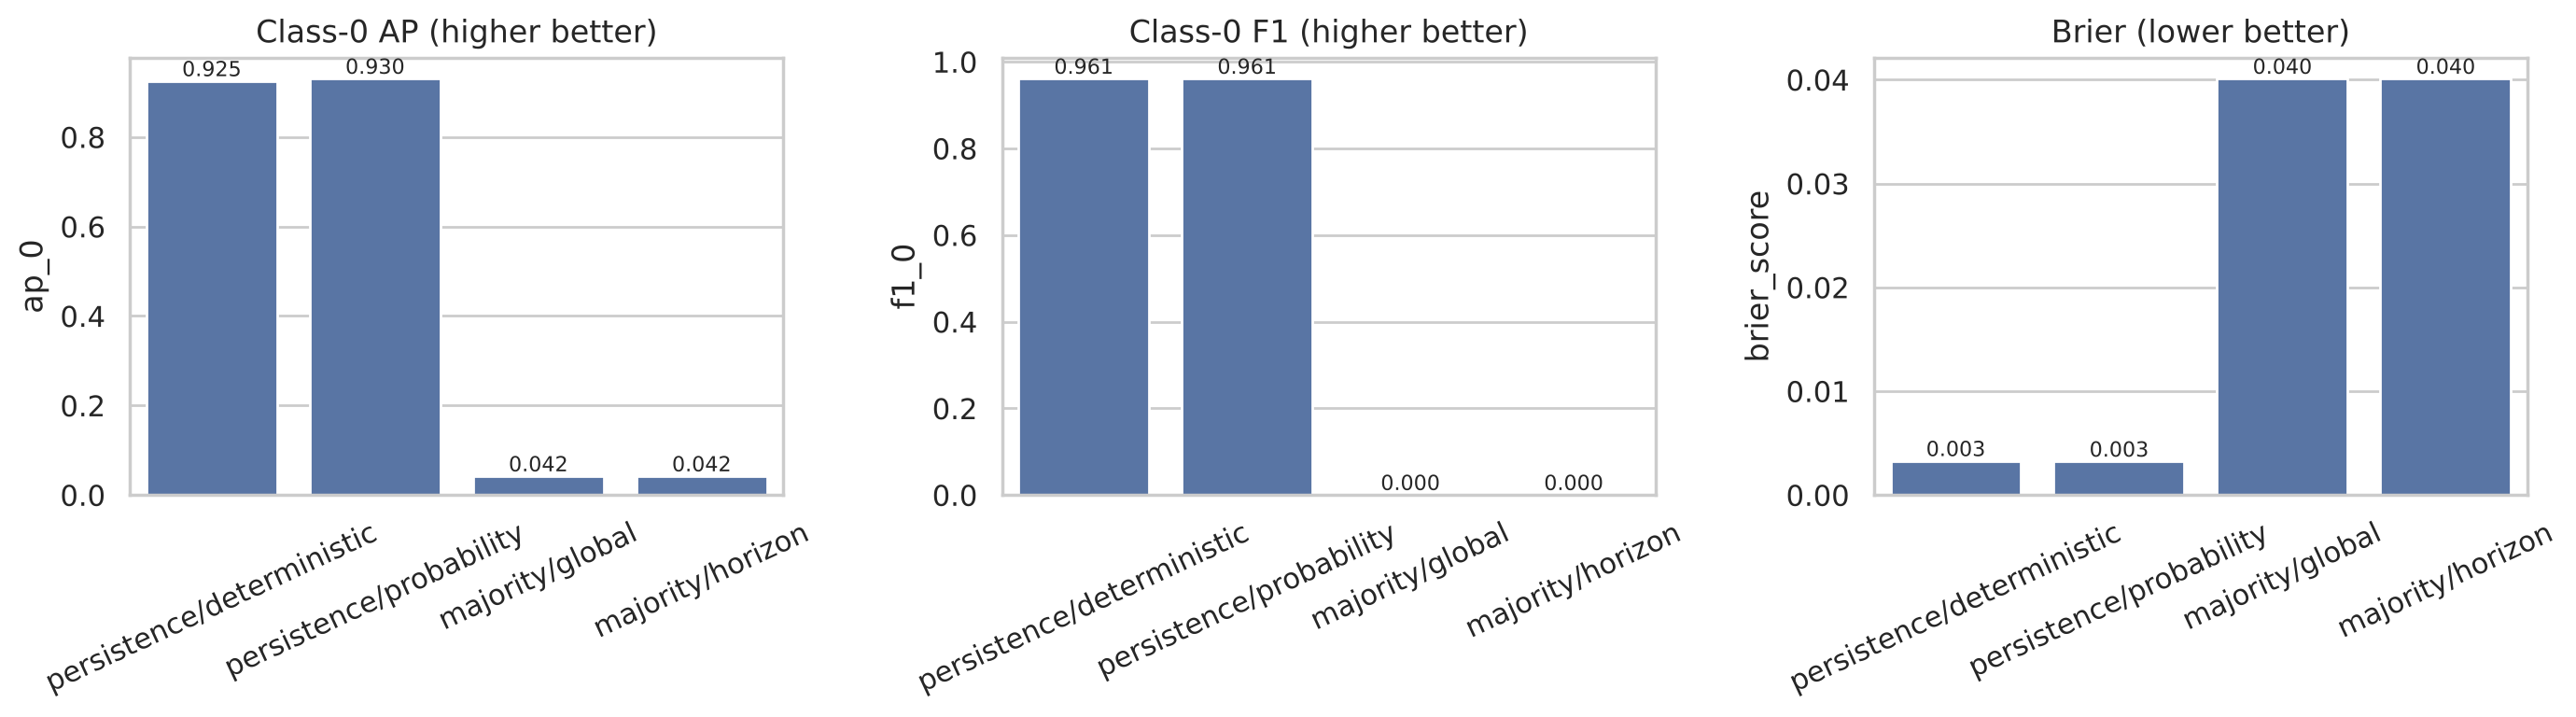

In [14]:
lab = overall.model_name + "/" + overall.model_version
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, m, t in zip(axes, ["ap_0","f1_0","brier_score"], ["Class-0 AP (higher better)","Class-0 F1 (higher better)","Brier (lower better)"]):
    sns.barplot(x=lab, y=overall[m].astype(float).fillna(0), ax=ax, color="#4C72B0")
    ax.set_title(t); ax.set_xlabel(""); ax.tick_params(axis="x", rotation=25)
    for c in ax.containers: ax.bar_label(c, fmt="%.3f", fontsize=8)
fig.tight_layout(); fig.savefig(FIGS / "baseline_comparison.png", dpi=150); plt.show()

## 9. Findings & Conclusion
- **Majority (global / horizon):** assigns ≈0.952 (fit data) to every row, always predicts *Available*. Accuracy equals the validation available share (~0.958) but Balanced Accuracy = 0.5, Class-0 recall = 0, Class-0 precision/F1 are undefined/0, ROC-AUC ≈ 0.5, and `AP_0` ≈ validation unavailable rate (0.042). It is the no-skill floor; accuracy alone is misleading with ~4% unavailable rows.
- **Persistence (deterministic):** because availability changes slowly, `current_idle > 0` is already a very strong rule (Balanced Accuracy ≈ 0.98, Class-0 F1 ≈ 0.96). Any learned model must beat this, not just the majority rate.
- **Persistence (probability):** at threshold 0.5 it yields **exactly the same class predictions** as the deterministic rule (the unavailable→available probability is ≈0.06–0.07 and available→available ≈0.996), so classification metrics are identical; the learned probabilities only improve the *ranking/probability* metrics (ROC-AUC, `AP_0`, Brier) slightly.
- Horizon effect: both persistence probabilities degrade as the horizon grows (unavailable→available rises from 5.5% at 30 min to 7.5% at 60 min).
- Unseen station 1948 is kept; it has no training history, but both baselines need no station identity, so it is evaluated like every other row.
- No validation/test label or statistic was used in any estimate.

## 10. Configuration and training metadata

In [15]:
t0 = time.perf_counter(); _ = bl.predict_all_baselines(validation, transitions, majority); infer_s = time.perf_counter() - t0
t0 = time.perf_counter(); _t = bl.fit_persistence_transitions(fit); _m = bl.fit_majority(fit); fit_s = time.perf_counter() - t0
config = {
 "models": {"persistence": ["deterministic", "probability"], "majority": ["global", "horizon"]},
 "threshold": 0.5, "seed": SEED, "y_prob": "P(Available=1)",
 "fit_period": {"start": "2022-12-01", "end_exclusive": "2022-12-30", "constraint": "time and target_time both inside"},
 "smoothing": {"formula": "(k + m*prior) / (n + m)", "m": bl.SMOOTHING_STRENGTH,
               "prior": "available share of the same fitting data (per horizon for persistence)", "empty_group": "fallback to prior"},
 "persistence_deterministic": "y_prob = 1.0 if current_idle > 0 else 0.0",
 "persistence_probability_table": "outputs/tables/persistence_transition_probabilities.csv",
 "majority_table": "outputs/tables/majority_class_proportions.csv",
 "global_majority_probability": p_major,
}
meta = {"environment": ENV, "fit_rows": int(len(fit)), "validation_rows": int(len(validation)),
        "fit_time_seconds": round(fit_s, 3), "inference_time_seconds_all_variants": round(infer_s, 3),
        "validation_stations": int(validation.station_id.nunique()), "unseen_validation_stations": [1948],
        "test_data_used": False}
(TABLES / "baselines_model_config.json").write_text(json.dumps(config, indent=2))
(TABLES / "baselines_training_metadata.json").write_text(json.dumps(meta, indent=2, default=str))
print(json.dumps(meta, indent=2, default=str))

{
  "environment": {
    "python": "3.13.18",
    "os": "Linux-6.18.44-fc-v880-x86_64-with-glibc2.39",
    "cpu_count": 2,
    "ram_gb": 7.8,
    "numpy": "2.5.3",
    "pandas": "3.0.5",
    "sklearn": "1.9.1",
    "n_jobs": 1,
    "seed": 42,
    "git_commit": null,
    "xgboost": "3.4.1"
  },
  "fit_rows": 2259325,
  "validation_rows": 618726,
  "fit_time_seconds": 0.177,
  "inference_time_seconds_all_variants": 0.142,
  "validation_stations": 90,
  "unseen_validation_stations": [
    1948
  ],
  "test_data_used": false
}
